# 46. Flow Matching with differentiable integration and endpoint supervision
Continue the trained FM 47 model under the same topology augmentation (KAIST original, replace-left, replace-right) and 60% remaining-LiDAR fault selection in two-IMU topologies. Train with a combined objective: nine-point analytic FM velocity supervision plus four-step differentiable Lie–Euler endpoint supervision. Validation, stochastic preflight, and checkpoint selection use the same combined objective.

The learned correction starts from identity on SE(3) and zero clock offset, integrates model-predicted velocities, and is applied on the left of the current physical calibration extrinsic. Internally the existing integrator composes the Lie increments on the right of the correction; do not change this convention.

Run policy: oracle integration test, endpoint-only gradient preflight, reversible stochastic learning check, then a short optional pilot. Full training and final held-out evaluation start disabled. If this method fails, investigate off-path correction-to-go targets separately, not as an untracked change in this experiment.

Important: the source project and checkpoints are local to your repository. Run the included oracle, gradient, and stochastic tests before enabling full training; they have not been executed against your KAIST installation here.

1. Imports and project root

In [1]:
from pathlib import Path
from dataclasses import asdict, fields, is_dataclass, replace
from collections import defaultdict
import gc
import math
import random
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from IPython.display import display

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Run from the nn-obs-calib repository root (must contain src/obscalib).")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SensorTopologyAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber, apply_prior_perturbation
from obscalib.calibration.update import CalibrationUpdater
from obscalib.config import CalibrationFlowIntegratorConfig, CalibrationFlowLossConfig, CalibrationPoolerConfig, MLPConfig, PooledCalibrationFlowConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch, TokenBatch
from obscalib.flow_matching.loss import calibration_velocity_loss
from obscalib.geometry.lie import se3_exp, se3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.models.pooled_calibration_flow_model import PooledCalibrationFlowModel
from obscalib.pipeline.window_step import WindowStep
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint

print("ROOT", ROOT, "| PyTorch", torch.__version__, "| CUDA", torch.cuda.is_available())

ROOT /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | PyTorch 2.7.1+cu126 | CUDA True


2. Settings: endpoint integration, FM loss, sampling, and independent run

In [21]:
RUN_NAME = "kaist_pooled_calibration_fm.4_differentiable_endpoint"
SOURCE_FM_CHECKPOINT = ROOT / "runs" / "kaist_pooled_calibration_fm.3_sensor_topology" / "best.pt"
SOURCE_REGRESSION_CHECKPOINT = ROOT / "runs" / "kaist_pooled_calibration_paired_002.26_refined_tau_single_topology_light" / "best.pt"
RUN_DIR = ROOT / "runs" / RUN_NAME
BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH = RUN_DIR / "best.pt", RUN_DIR / "last.pt"

SEED = 12345
TRAIN_AUG_SEED, VAL_AUG_SEED, TEST_AUG_SEED = 23456, 34567, 45678
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32
CALIBRATION_KEYS = ("imu", "lidar", "lidar_right")
MEASUREMENT_DIM = 6
WINDOW_DURATION_S, WINDOW_STRIDE_S = 5.0, 5.0
MAX_SAMPLES_PER_SENSOR = 700
BATCH_SIZE, NUM_WORKERS = 4, 0

# Dense-path fine-tuning from FM46. Fresh optimizer, unchanged physical augmentations and FM weights.
HEAD_LEARNING_RATE = 2e-5
BACKBONE_LEARNING_RATE = 2e-6
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0
GRADIENT_ACCUMULATION_STEPS = 4  # Four parent batches per optimizer update
FLOW_PATH_NUM_POINTS = 9  # Uniform analytic flow path for velocity loss
TRAIN_INTEGRATION_STEPS = 4  # Differentiable Lie-Euler steps (inference is unchanged)
TRAIN_INTEGRATION_METHOD = "euler"
VELOCITY_LOSS_WEIGHT = 1.0
ENDPOINT_LOSS_WEIGHT = 0.2
FULL_TRAIN_TOPOLOGY = "mixture"  # Change to "replace_lidar_right" for a focused pilot
FULL_TRAIN_REGIME = "mixed"     # Change to "fine" for a focused pilot
TRAIN_EPOCHS = 200
LR_REDUCE_STEPS, LR_REDUCE_FACTOR = 10, 0.5
MAX_TRAIN_BATCHES_PER_EPOCH = None
MAX_VAL_BATCHES_PER_EPOCH = None
REGIME_VALIDATION_BATCHES = 3
RUN_FULL_TRAINING = True
RUN_FINAL_EVALUATION = True
REQUIRE_PRECHECK_PASS_FOR_FULL_TRAINING = False

FM_INTEGRATION_STEPS = 16
FM_INTEGRATION_METHOD = "midpoint"
RUN_INTEGRATION_ABLATION = True
ABLATION_STEPS = (4, 8, 16, 32)
EVAL_WINDOWS_PER_SEQUENCE = 3

# EXACT prior-corruption distribution from notebook 44.
FINE_PRIOR_PROBABILITY = 0.40
FINE_ROTATION_MAX_RAD = np.deg2rad(60.0)
FINE_ROTATION_SCALE_RAD = np.deg2rad(30.0)
FINE_TIME_OFFSET_MAX_S, FINE_TIME_OFFSET_SCALE_S = 0.500, 0.250
COARSE_ROTATION_MAX_RAD = np.deg2rad(179.0)
COARSE_TIME_OFFSET_MAX_S, COARSE_TIME_OFFSET_SCALE_S = 0.500, 0.250
STUDENT_T_DEGREES_OF_FREEDOM = 3
TRUE_ROTATION_MAX_RAD = np.deg2rad(180.0)
TRUE_TIME_OFFSET_MAX_S = 0.030

# EXACT topology modes, frequencies and synthetic mounting policy from notebook 42.
TOPOLOGY_MODES = ("original", "replace_lidar", "replace_lidar_right")
TOPOLOGY_PROBABILITIES = (0.50, 0.25, 0.25)
TOPOLOGY_SYNTHETIC_MOUNT_MAX_DEG = 180.0
TOPOLOGY_SYNTH_GYRO_NOISE_STD = 0.0
TOPOLOGY_SYNTH_ACCEL_NOISE_STD = 0.0
EXPECTED_KEYS_BY_TOPOLOGY = {
    "original": frozenset(("imu", "lidar", "lidar_right")),
    "replace_lidar": frozenset(("imu", "imu_synth", "lidar_right")),
    "replace_lidar_right": frozenset(("imu", "lidar", "imu_synth")),
}
assert np.isclose(sum(TOPOLOGY_PROBABILITIES), 1.0) and all(p > 0 for p in TOPOLOGY_PROBABILITIES)
assert FINE_ROTATION_MAX_RAD <= COARSE_ROTATION_MAX_RAD < np.pi

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)
if not SOURCE_FM_CHECKPOINT.is_file():
    raise FileNotFoundError(f"Source FM checkpoint missing: {SOURCE_FM_CHECKPOINT}; change SOURCE_FM_CHECKPOINT to your selected FM46/FM4 checkpoint.")
RUN_DIR.mkdir(parents=True, exist_ok=True)
print("Starting FM weights:", SOURCE_FM_CHECKPOINT)
print("Dense analytical FM path points:", FLOW_PATH_NUM_POINTS)
print("Topology probabilities:", dict(zip(TOPOLOGY_MODES, TOPOLOGY_PROBABILITIES)))
print("Fine/coarse:", FINE_PRIOR_PROBABILITY, 1-FINE_PRIOR_PROBABILITY, "| 60°/179°")
print("Dense-path FM + differentiable endpoint (four-step Euler); full training", RUN_FULL_TRAINING)

Starting FM weights: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.3_sensor_topology/best.pt
Dense analytical FM path points: 9
Topology probabilities: {'original': 0.5, 'replace_lidar': 0.25, 'replace_lidar_right': 0.25}
Fine/coarse: 0.4 0.6 | 60°/179°
Dense-path FM + differentiable endpoint (four-step Euler); full training True


3. KAIST datasets and unchanged rig references

In [3]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")
TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
VAL_NAMES = ["Urban26", "Urban28"]
TEST_NAMES = ["Urban38", "Urban39"]
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES
assert len(set(ALL_SEQUENCE_NAMES)) == len(ALL_SEQUENCE_NAMES)

T_B_L = np.array([[-0.514066, -0.702201, -0.492595, -0.440699], [0.486485, -0.711672, 0.506809, 0.397052], [-0.706447, 0.0208933, 0.707457, 1.90953], [0., 0., 0., 1.]], dtype=float)
T_B_L_right = np.array([[-0.512152, 0.699241, -0.498761, -0.449885], [-0.494811, -0.714859, -0.494104, -0.416713], [-0.702041, -0.0062642, 0.712109, 1.91294], [0., 0., 0., 1.]], dtype=float)
T_I_B = np.array([[1., 0., 0., -0.07], [0., 1., 0., 0.], [0., 0., 1., 1.7], [0., 0., 0., 1.]], dtype=float)
rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0, T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Right-LiDAR pose CSV required by 002.24 architecture: {spec.name}: {spec.lidar_right_pose_csv}")
spec_by_name = {spec.name: spec for spec in all_specs}

def make_dataset(names):
    return KAISTCalibrationDataset([spec_by_name[name] for name in names], rig_calibration, windowing_config, measurement_dtype=DTYPE, source_timestamp_dtype=torch.float64, window_timestamp_dtype=DTYPE)

train_dataset, val_dataset, test_dataset = (make_dataset(names) for names in (TRAIN_NAMES, VAL_NAMES, TEST_NAMES))
for name, ds in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    if tuple(ds.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f"Unexpected calibration keys for {name}: {ds.calibration_keys}")
    print(name, len(ds), "windows")

train_shuffle_generator = torch.Generator().manual_seed(SEED)
train_loader = make_kaist_dataloader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
val_loader = make_kaist_dataloader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)

train 2006 windows
validation 418 windows
test 699 windows


4. Topology-aware physical augmentation and notebook-44 priors

Each physical window first chooses exactly one topology. Homogeneous examples are grouped so the augmentation pipeline can change stream/calibration schemas, then each group draws its own fine/coarse mask per physical example. We never perturb an already-updated calibration as the truth source.

The topology pipeline is taken from notebook 42; the fine/coarse priors and target semantics are taken from notebook 44. Common-frame rotation stays disabled to isolate topology effects.

In [4]:
true_calibration_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True, probability=1.0, rotation_probability=1.0, translation_probability=0.0, time_offset_probability=1.0,
        rotation=PerturbationMagnitudeConfig(maximum=TRUE_ROTATION_MAX_RAD),
        time_offset=PerturbationMagnitudeConfig(maximum=TRUE_TIME_OFFSET_MAX_S),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)

def topology_config_for_mode(mode: str) -> SensorTopologyAugmentationConfig:
    if mode not in TOPOLOGY_MODES:
        raise ValueError(mode)
    return SensorTopologyAugmentationConfig(
        enabled=(mode != "original"), replacement_probability=1.0,
        replace_first_lidar_probability=1.0 if mode == "replace_lidar" else 0.0,
        maximum_mount_rotation_deg=TOPOLOGY_SYNTHETIC_MOUNT_MAX_DEG,
        synthetic_gyro_noise_std=TOPOLOGY_SYNTH_GYRO_NOISE_STD,
        synthetic_accel_noise_std=TOPOLOGY_SYNTH_ACCEL_NOISE_STD,
    )

physical_augmenters = {
    mode: AugmentationPipeline(replace(true_calibration_config, sensor_topology=topology_config_for_mode(mode)))
    for mode in TOPOLOGY_MODES
}

fine_prior_config = PriorPerturbationConfig(
    enabled=True, probability=1.0,
    rotation=PerturbationMagnitudeConfig(maximum=FINE_ROTATION_MAX_RAD, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=FINE_ROTATION_SCALE_RAD, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    translation=None,
    time_offset=PerturbationMagnitudeConfig(maximum=FINE_TIME_OFFSET_MAX_S, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=FINE_TIME_OFFSET_SCALE_S, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False,
)
coarse_prior_config = PriorPerturbationConfig(
    enabled=True, probability=1.0,
    rotation=PerturbationMagnitudeConfig(maximum=COARSE_ROTATION_MAX_RAD, distribution=PerturbationDistribution.UNIFORM),
    translation=None,
    time_offset=PerturbationMagnitudeConfig(maximum=COARSE_TIME_OFFSET_MAX_S, distribution=PerturbationDistribution.UNIFORM, scale=COARSE_TIME_OFFSET_SCALE_S, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False,
)
fine_prior_perturber = CalibrationPriorPerturber(fine_prior_config)
coarse_prior_perturber = CalibrationPriorPerturber(coarse_prior_config)

def augmentation_generator(seed: int):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))

def clone_with_current_calibration(window: WindowBatch, new_calibration):
    return WindowBatch(streams=dict(window.streams), current_calibration=new_calibration, metadata=dict(window.metadata), targets=None if window.targets is None else dict(window.targets), dataset_indices=window.dataset_indices)

# Probability that each calibration receives the ONE prior fault in a physical window.
# Keep original KAIST unchanged; emphasize the remaining real LiDAR in 2-IMU/1-LiDAR cases.
FAULT_KEY_WEIGHTS = {
    frozenset(("imu", "lidar", "lidar_right")): {"imu": 1.0, "lidar": 1.0, "lidar_right": 1.0},
    frozenset(("imu", "imu_synth", "lidar_right")): {"imu": 0.20, "imu_synth": 0.20, "lidar_right": 0.60},
    frozenset(("imu", "lidar", "imu_synth")): {"imu": 0.20, "lidar": 0.60, "imu_synth": 0.20},
}

def sample_fine_coarse_deltas(true_states, generator: torch.Generator, regime: str = "mixed"):
    if regime not in {"mixed", "fine", "coarse"}:
        raise ValueError(regime)

    keys = tuple(true_states)
    probability_by_key = FAULT_KEY_WEIGHTS.get(frozenset(keys))
    if probability_by_key is None:
        raise ValueError(f"No fault-selection weights for calibration keys {keys}")

    template = next(iter(true_states.values())).transform
    n = len(template)
    weights = torch.tensor([probability_by_key[key] for key in keys], device=template.device, dtype=torch.float32)
    weights = weights / weights.sum()
    selected_key_indices = torch.multinomial(weights, n, replacement=True, generator=generator)

    if regime == "mixed":
        fine_mask = torch.rand(n, device=template.device, generator=generator) < FINE_PRIOR_PROBABILITY
    else:
        fine_mask = torch.full((n,), regime == "fine", device=template.device, dtype=torch.bool)

    # Reuse the existing perturbers on single-key dictionaries. This preserves their
    # exact Student-t/uniform SO(3) and tau distributions while controlling key choice.
    xi, tau = {}, {}
    for key_index, key in enumerate(keys):
        singleton = {key: true_states[key]}
        if regime != "coarse":
            _, fine_xi, fine_tau = fine_prior_perturber(singleton, generator=generator)
        if regime != "fine":
            _, coarse_xi, coarse_tau = coarse_prior_perturber(singleton, generator=generator)

        if regime == "fine":
            chosen_xi, chosen_tau = fine_xi[key], fine_tau[key]
        elif regime == "coarse":
            chosen_xi, chosen_tau = coarse_xi[key], coarse_tau[key]
        else:
            chosen_xi = torch.where(fine_mask[:, None], fine_xi[key], coarse_xi[key])
            chosen_tau = torch.where(fine_mask[:, None], fine_tau[key], coarse_tau[key])

        selected = (selected_key_indices == key_index)[:, None]
        xi[key] = torch.where(selected, chosen_xi, torch.zeros_like(chosen_xi))
        tau[key] = torch.where(selected, chosen_tau, torch.zeros_like(chosen_tau))

    return xi, tau, fine_mask

@torch.no_grad()
def augment_topology_window(base_window: WindowBatch, generator: torch.Generator, *, topology: str, regime: str = "mixed") -> WindowBatch:
    if topology not in TOPOLOGY_MODES:
        raise ValueError(topology)
    physical = physical_augmenters[topology](base_window, generator=generator).augmented_window
    truth_states = physical.current_calibration
    assert frozenset(truth_states) == EXPECTED_KEYS_BY_TOPOLOGY[topology], (topology, tuple(truth_states))
    xi, tau, _ = sample_fine_coarse_deltas(truth_states, generator, regime=regime)
    return clone_with_current_calibration(physical, apply_prior_perturbation(truth_states, xi, tau))

def correction_targets(window: WindowBatch):
    if window.targets is None:
        raise ValueError("Expected truth targets after topology/true-calibration augmentation")
    targets_xi, targets_tau = {}, {}
    for key, state in window.current_calibration.items():
        target = window.targets[key]
        if target.next_transform is None or target.next_time_offset is None:
            raise ValueError(f"Missing correction truth for {key}")
        targets_xi[key] = se3_log(target.next_transform @ torch.linalg.inv(state.transform))
        targets_tau[key] = target.next_time_offset - state.time_offset
    return targets_xi, targets_tau

print("Physical pipeline:", {name: p.config.sensor_topology for name, p in physical_augmenters.items()})
print("Unchanged fine/coarse priors:", fine_prior_config, coarse_prior_config)

Physical pipeline: {'original': SensorTopologyAugmentationConfig(enabled=False, replacement_probability=1.0, replace_first_lidar_probability=0.0, source_imu_key='imu', lidar_keys=('lidar', 'lidar_right'), synthetic_calibration_key='imu_synth', synthetic_gyro_stream='gyro_synth', synthetic_accel_stream='accel_synth', maximum_mount_rotation_deg=180.0, synthetic_gyro_noise_std=0.0, synthetic_accel_noise_std=0.0), 'replace_lidar': SensorTopologyAugmentationConfig(enabled=True, replacement_probability=1.0, replace_first_lidar_probability=1.0, source_imu_key='imu', lidar_keys=('lidar', 'lidar_right'), synthetic_calibration_key='imu_synth', synthetic_gyro_stream='gyro_synth', synthetic_accel_stream='accel_synth', maximum_mount_rotation_deg=180.0, synthetic_gyro_noise_std=0.0, synthetic_accel_noise_std=0.0), 'replace_lidar_right': SensorTopologyAugmentationConfig(enabled=True, replacement_probability=1.0, replace_first_lidar_probability=0.0, source_imu_key='imu', lidar_keys=('lidar', 'lidar_ri

## 5. Per-example topology mixture and schema-safe batch splitting
The original KAIST WindowBatch has one schema. As in notebook 42, randomly choose a topology per physical example and process each set as a separate subbatch. Weight each loss by subbatch_size / original_batch_size before backward, so rare topologies are neither lost nor overcounted. The dataset_indices metadata follows the selection as well.

In [5]:
def topology_slice_batch(window: WindowBatch, positions: torch.Tensor) -> WindowBatch:
    n = len(next(iter(window.current_calibration.values())).transform)
    if positions.numel() == 0:
        raise ValueError("Cannot create an empty topology group")
    positions_cpu = positions.detach().cpu().tolist()
    original_indices = window.dataset_indices
    if isinstance(original_indices, torch.Tensor):
        selected_indices = original_indices.index_select(0, positions.to(device=original_indices.device))
    elif original_indices is not None and hasattr(original_indices, "__len__") and len(original_indices) == n:
        selected = [original_indices[i] for i in positions_cpu]
        selected_indices = tuple(selected) if isinstance(original_indices, tuple) else selected
    else:
        selected_indices = original_indices

    def select(item):
        if isinstance(item, torch.Tensor) and item.ndim > 0 and item.shape[0] == n:
            return item.index_select(0, positions.to(device=item.device))
        if is_dataclass(item) and not isinstance(item, type):
            updates = {field.name: (selected_indices if isinstance(item, WindowBatch) and field.name == "dataset_indices" else select(getattr(item, field.name))) for field in fields(item) if field.init}
            return replace(item, **updates)
        if isinstance(item, dict):
            return {key: select(value) for key, value in item.items()}
        return item

    return select(window)

def topology_groups(base_window: WindowBatch, generator: torch.Generator, mode: str = "mixture"):
    sample_transform = next(iter(base_window.current_calibration.values())).transform
    n = len(sample_transform)
    if mode == "mixture":
        drawn = torch.rand(n, device=sample_transform.device, generator=generator)
        ids = torch.where(drawn < TOPOLOGY_PROBABILITIES[0], 0, torch.where(drawn < sum(TOPOLOGY_PROBABILITIES[:2]), 1, 2))
    elif mode in TOPOLOGY_MODES:
        ids = torch.full((n,), TOPOLOGY_MODES.index(mode), device=sample_transform.device, dtype=torch.long)
    else:
        raise ValueError(mode)
    return [(name, topology_slice_batch(base_window, positions)) for i, name in enumerate(TOPOLOGY_MODES) if (positions := torch.nonzero(ids == i, as_tuple=False).flatten()).numel()]

# Keep the original input batch intact: topology grouping must be a partition of physical examples.
test_base = window_batch_to(next(iter(train_loader)), DEVICE, dtype=DTYPE)
groups = topology_groups(test_base, augmentation_generator(TRAIN_AUG_SEED + 18))
assert sum(len(next(iter(w.current_calibration.values())).transform) for _, w in groups) == len(next(iter(test_base.current_calibration.values())).transform)
for mode, group in groups:
    print("Partition", mode, "n=", len(next(iter(group.current_calibration.values())).transform))

Partition original n= 2
Partition replace_lidar_right n= 2


## 6. Load the trained FM46 checkpoint and unfreeze all components
Keep the transformer, pooler, MLPBody, and velocity head from the source checkpoint. A fresh optimizer is created for notebook 47; the regression checkpoint is reserved for comparison.

In [6]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=8, d_model=128, n_heads=8, num_layers=12, dim_feedforward=512, dropout=0.0, num_summary_tokens=1, activation="gelu"),
    pooler=CalibrationPoolerConfig(n_heads=8, dropout=0.0, calibration_context_dim=0),
    mlp=MLPConfig(hidden_dims=(256, 128), output_dim=128, activation="gelu", dropout=0.0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=(128, 64), activation="gelu", dropout=0.0),
)
flow_config = PooledCalibrationFlowConfig(
    backbone=model_config,
    integrator=CalibrationFlowIntegratorConfig(num_steps=FM_INTEGRATION_STEPS, method=FM_INTEGRATION_METHOD, ablation_steps=ABLATION_STEPS),
    loss=CalibrationFlowLossConfig(rotation_scale_rad=np.deg2rad(5.0), translation_scale_m=0.05, time_offset_scale_s=0.05, rotation_weight=2.0, translation_weight=1.0, time_offset_weight=1.0, active_rotation_weight=0.75),
    freeze_backbone_initially=False,
)
fm_model = PooledCalibrationFlowModel(flow_config.backbone, **flow_config.model_kwargs()).to(device=DEVICE, dtype=DTYPE)
load_training_checkpoint(SOURCE_FM_CHECKPOINT, model=fm_model, map_location=DEVICE, restore_rng_state=False)
fm_model.freeze_feature_extractor(False)
fm_loss_weights = flow_config.loss.to_loss_weights()

for module in (fm_model.transformer_encoder, fm_model.pooler, fm_model.mlp_body, fm_model.head):
    assert all(p.requires_grad for p in module.parameters())
print("FM checkpoint loaded:", SOURCE_FM_CHECKPOINT)
print("FM parameters:", sum(p.numel() for p in fm_model.parameters()), "trainable:", sum(p.numel() for p in fm_model.parameters() if p.requires_grad))

FM checkpoint loaded: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.3_sensor_topology/best.pt
FM parameters: 2555399 trainable: 2555399


## 7. Dynamic tokenizer and joint FM/endpoint supervision

In [7]:
class _CapturedTokens(Exception):
    pass

class _TokenCaptureModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.tokens = None
        self.context = None

    def forward(self, tokens, calibration_context=None, **kwargs):
        self.tokens = tokens
        self.context = calibration_context
        raise _CapturedTokens()

geometry_processor = GeometryProcessor()
calibration_updater = CalibrationUpdater()
capture_model = _TokenCaptureModel()

def tokenize_window(window: WindowBatch):
    # Topology-dependent calibration key set/order MUST be decided after augmentation.
    calibration_keys = tuple(window.current_calibration)
    step = WindowStep(geometry_processor=geometry_processor, tokenizer=Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=calibration_keys), model=capture_model, calibration_updater=calibration_updater)
    capture_model.tokens = None
    capture_model.context = None
    try:
        step(window)
    except _CapturedTokens:
        pass
    if capture_model.tokens is None:
        raise RuntimeError("WindowStep did not call model: failed to capture tokens")
    if tuple(capture_model.tokens.calibration_keys) != calibration_keys:
        raise AssertionError((calibration_keys, capture_model.tokens.calibration_keys))
    return capture_model.tokens, capture_model.context

def flow_supervision(window: WindowBatch, *, generator: torch.Generator, model=None):
    model = fm_model if model is None else model
    with torch.no_grad():
        tokens, context = tokenize_window(window)
        target_xi, target_tau = correction_targets(window)
    output = model.forward_flow_matching(tokens, target_xi, target_tau, calibration_context=context, generator=generator)
    loss = calibration_velocity_loss(output.predicted_velocity, output.flow_batch.target_velocity, weights=fm_loss_weights)
    return loss, output

def dense_path_supervision(window: WindowBatch, *, generator=None, model=None, num_points=None):
    """Analytic velocity loss at a complete uniform path grid, without ODE integration.

    The costly transformer/pooler/MLP feature extractor is executed ONCE per
    augmented window. Its features remain attached to autograd. The lightweight
    FM velocity head is evaluated at every t in linspace(0, 1, num_points).

    Loss uses the existing calibration_velocity_loss unchanged, including
    active_rotation_weight. Averaging occurs across [time, example, key].
    """
    model = fm_model if model is None else model
    num_points = FLOW_PATH_NUM_POINTS if num_points is None else int(num_points)
    if num_points < 2:
        raise ValueError("Dense FM training requires at least two path points")
    with torch.no_grad():
        tokens, context = tokenize_window(window)
        target_xi_by_key, target_tau_by_key = correction_targets(window)

    shared, stacked_context = model.encode_calibration_features(tokens, context)
    keys = tuple(tokens.calibration_keys)
    delta_xi = torch.stack([target_xi_by_key[key] for key in keys], dim=1)
    delta_tau = torch.stack([target_tau_by_key[key] for key in keys], dim=1)
    batch_size, num_calibrations, feature_dim = shared.shape
    assert delta_xi.shape == (batch_size, num_calibrations, 6)
    assert delta_tau.shape == (batch_size, num_calibrations, 1)

    # Shared t across sensors in a physical window, but supervise EVERY window
    # and calibration at EVERY evenly spaced path point.
    grid = torch.linspace(0.0, 1.0, num_points, device=shared.device, dtype=shared.dtype)
    time = grid.view(num_points, 1, 1, 1).expand(num_points, batch_size, num_calibrations, 1)
    correction_xi = time * delta_xi.unsqueeze(0)
    correction_tau = time * delta_tau.unsqueeze(0)

    all_shared = shared.unsqueeze(0).expand(num_points, -1, -1, -1).reshape(num_points * batch_size, num_calibrations, feature_dim)
    all_context = None if stacked_context is None else stacked_context.unsqueeze(0).expand(num_points, -1, -1, -1).reshape(num_points * batch_size, num_calibrations, stacked_context.shape[-1])
    predicted = model.velocity_from_features(
        all_shared,
        correction_xi.reshape(num_points * batch_size, num_calibrations, 6),
        correction_tau.reshape(num_points * batch_size, num_calibrations, 1),
        time.reshape(num_points * batch_size, num_calibrations, 1),
        all_context,
    ).reshape(num_points, batch_size, num_calibrations, 7)

    truth = torch.cat((delta_xi, delta_tau), dim=-1).unsqueeze(0).expand_as(predicted)
    losses = calibration_velocity_loss(predicted, truth, weights=fm_loss_weights)
    return losses, predicted

@torch.no_grad()
def model_predictions(model, window, steps=FM_INTEGRATION_STEPS):
    tokens, context = tokenize_window(window)
    if isinstance(model, PooledCalibrationFlowModel):
        return model(tokens, context, num_steps=steps, method=FM_INTEGRATION_METHOD)
    return model(tokens, context)

from dataclasses import dataclass
from obscalib.flow_matching.lie_integrator import integrate_calibration_flow

@dataclass
class JointFMEndpointLoss:
    total: torch.Tensor
    velocity: object
    endpoint: torch.Tensor
    endpoint_rotation: torch.Tensor
    endpoint_translation: torch.Tensor
    endpoint_tau: torch.Tensor
    lidar_active_rotation_deg: torch.Tensor
    lidar_healthy_rotation_deg: torch.Tensor

    def detached_metrics(self):
        metrics = self.velocity.detached_metrics()
        metrics.update({
            "loss_combined_total": float(self.total.detach()),
            "loss_endpoint_total": float(self.endpoint.detach()),
            "loss_endpoint_rotation": float(self.endpoint_rotation.detach()),
            "loss_endpoint_translation": float(self.endpoint_translation.detach()),
            "loss_endpoint_time_offset": float(self.endpoint_tau.detach()),
            "endpoint_lidar_active_rotation_deg": float(self.lidar_active_rotation_deg.detach()),
            "endpoint_lidar_healthy_rotation_deg": float(self.lidar_healthy_rotation_deg.detach()),
        })
        return metrics


def endpoint_loss_from_integration(window, flow_result, keys, target_xi, *, weights):
    """Physical corrected extrinsics and clocks; no detach anywhere on predicted path."""
    current = torch.stack([window.current_calibration[key].transform for key in keys], dim=1)
    desired = torch.stack([window.targets[key].next_transform for key in keys], dim=1)
    current_tau = torch.stack([window.current_calibration[key].time_offset for key in keys], dim=1)
    desired_tau = torch.stack([window.targets[key].next_time_offset for key in keys], dim=1)
    corrected = flow_result.correction_transform @ current
    predicted_tau = current_tau + flow_result.delta_tau

    # SO(3) geodesic angle is stable near identity and bounded by pi.
    residual_rotation = desired[..., :3, :3] @ corrected[..., :3, :3].transpose(-1, -2)
    skew = torch.stack((
        residual_rotation[..., 2, 1] - residual_rotation[..., 1, 2],
        residual_rotation[..., 0, 2] - residual_rotation[..., 2, 0],
        residual_rotation[..., 1, 0] - residual_rotation[..., 0, 1],
    ), dim=-1)
    sin_angle = 0.5 * torch.linalg.vector_norm(skew, dim=-1)
    cos_angle = 0.5 * (residual_rotation.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1)
    rotation_angle = torch.atan2(sin_angle, cos_angle)
    translation_error = corrected[..., :3, 3] - desired[..., :3, 3]
    tau_error = predicted_tau - desired_tau

    rotation_loss = (rotation_angle / weights.rotation_scale_rad).square().mean()
    translation_loss = (translation_error / weights.translation_scale_m).square().mean()
    tau_loss = (tau_error / weights.time_offset_scale_s).square().mean()
    combined = weights.rotation_weight * rotation_loss + weights.translation_weight * translation_loss + weights.time_offset_weight * tau_loss

    active_angles, healthy_angles = [], []
    for index, key in enumerate(keys):
        if key.startswith("lidar"):
            active_mask = torch.linalg.vector_norm(target_xi[key][:, :3], dim=-1) > 1e-6
            if bool(active_mask.any()): active_angles.append(torch.rad2deg(rotation_angle[:, index][active_mask]))
            if bool((~active_mask).any()): healthy_angles.append(torch.rad2deg(rotation_angle[:, index][~active_mask]))
    nan_metric = rotation_angle.detach().new_tensor(float("nan"))
    active = torch.cat(active_angles).mean() if active_angles else nan_metric
    healthy = torch.cat(healthy_angles).mean() if healthy_angles else nan_metric
    return combined, rotation_loss, translation_loss, tau_loss, active, healthy


def joint_flow_endpoint_supervision(window, *, generator=None, model=None):
    """Single encoder pass with nine-time analytic supervision plus a differentiable ODE.

    Training uses 4 Euler steps; inference uses the unchanged 16-step midpoint.
    """
    model = fm_model if model is None else model
    with torch.no_grad():
        tokens, context = tokenize_window(window)
        target_xi, target_tau = correction_targets(window)

    shared, stacked_context = model.encode_calibration_features(tokens, context)
    keys = tuple(tokens.calibration_keys)
    delta_xi = torch.stack([target_xi[key] for key in keys], dim=1)
    delta_tau = torch.stack([target_tau[key] for key in keys], dim=1)
    batch_size, num_calibrations, feature_dim = shared.shape
    num_points = FLOW_PATH_NUM_POINTS

    grid = torch.linspace(0.0, 1.0, num_points, device=shared.device, dtype=shared.dtype)
    times = grid.view(num_points, 1, 1, 1).expand(num_points, batch_size, num_calibrations, 1)
    shared_repeated = shared.unsqueeze(0).expand(num_points, -1, -1, -1).reshape(num_points * batch_size, num_calibrations, feature_dim)
    context_repeated = None if stacked_context is None else stacked_context.unsqueeze(0).expand(num_points, -1, -1, -1).reshape(num_points * batch_size, num_calibrations, stacked_context.shape[-1])
    predicted = model.velocity_from_features(
        shared_repeated,
        (times * delta_xi.unsqueeze(0)).reshape(num_points * batch_size, num_calibrations, 6),
        (times * delta_tau.unsqueeze(0)).reshape(num_points * batch_size, num_calibrations, 1),
        times.reshape(num_points * batch_size, num_calibrations, 1),
        context_repeated,
    ).reshape(num_points, batch_size, num_calibrations, 7)
    target_velocity = torch.cat((delta_xi, delta_tau), dim=-1).unsqueeze(0).expand_as(predicted)
    velocity = calibration_velocity_loss(predicted, target_velocity, weights=fm_loss_weights)

    # No torch.no_grad: gradient must pass through predicted states and encoder.
    result = model.integrate_from_features(shared, stacked_context, num_steps=TRAIN_INTEGRATION_STEPS, method=TRAIN_INTEGRATION_METHOD)
    endpoint, endpoint_rotation, endpoint_translation, endpoint_tau, active, healthy = endpoint_loss_from_integration(window, result, keys, target_xi, weights=fm_loss_weights)
    total = VELOCITY_LOSS_WEIGHT * velocity.total + ENDPOINT_LOSS_WEIGHT * endpoint
    if not bool(torch.isfinite(total.detach())):
        raise FloatingPointError("Nonfinite joint loss: inspect Lie logarithm, flow field, and endpoint")
    return JointFMEndpointLoss(total, velocity, endpoint, endpoint_rotation, endpoint_translation, endpoint_tau, active, healthy), result


## 8. Topology semantics, target ordering, and full-backbone gradient preflight
Smoke-test all three topology modes individually. This checks synthetic-key routing in both tokenization and flow supervision, including target-velocity ordering. After that, verify gradients propagate into transformer, pooler, MLPBody and FM head. No optimizer step is taken.

In [8]:
for mode_idx, mode in enumerate(TOPOLOGY_MODES):
    window = augment_topology_window(test_base, augmentation_generator(TRAIN_AUG_SEED + 51 + mode_idx), topology=mode, regime="mixed")
    target_xi, target_tau = correction_targets(window)
    tokens, context = tokenize_window(window)
    assert frozenset(tokens.calibration_keys) == EXPECTED_KEYS_BY_TOPOLOGY[mode]
    assert tokens.x.shape[-1] == 8
    with torch.no_grad():
        result = fm_model.forward_flow_matching(tokens, target_xi, target_tau, calibration_context=context, generator=augmentation_generator(TRAIN_AUG_SEED + 110 + mode_idx))
    assert result.predicted_velocity.shape == (len(tokens.x), len(tokens.calibration_keys), 7)
    torch.testing.assert_close(result.flow_batch.target_velocity[..., :6], torch.stack([target_xi[k] for k in tokens.calibration_keys], dim=1))
    torch.testing.assert_close(result.flow_batch.target_velocity[..., 6:], torch.stack([target_tau[k] for k in tokens.calibration_keys], dim=1))
    print(f"{mode:22s} {tuple(tokens.x.shape)} calibration_keys={tuple(tokens.calibration_keys)}: PASS")

fm_model.train()
fm_model.zero_grad(set_to_none=True)
grad_case = augment_topology_window(test_base, augmentation_generator(TRAIN_AUG_SEED + 200), topology="replace_lidar", regime="coarse")
grad_losses, _ = dense_path_supervision(grad_case, generator=augmentation_generator(TRAIN_AUG_SEED + 201))
grad_losses.total.backward()
for block_name in ("transformer_encoder", "pooler", "mlp_body", "head"):
    gradients = [p.grad for p in getattr(fm_model, block_name).parameters() if p.grad is not None]
    assert gradients and all(torch.isfinite(g).all() for g in gradients), block_name
    print(f"{block_name:20s} gradient norm={sum(g.square().sum().item() for g in gradients)**0.5:.4g}")
fm_model.zero_grad(set_to_none=True)
print("Dynamic topology and DENSE-PATH FM gradient preflight: PASS")

original               (4, 1097, 8) calibration_keys=('imu', 'lidar', 'lidar_right'): PASS
replace_lidar          (4, 2048, 8) calibration_keys=('imu', 'imu_synth', 'lidar_right'): PASS
replace_lidar_right    (4, 2049, 8) calibration_keys=('imu', 'lidar', 'imu_synth'): PASS
transformer_encoder  gradient norm=56.64
pooler               gradient norm=19.02
mlp_body             gradient norm=74.02
head                 gradient norm=118.8
Dynamic topology and DENSE-PATH FM gradient preflight: PASS


## 8a. Required oracle integration and endpoint-gradient preflight
Oracle constant velocities must reproduce physical target calibrations using the repository integrator. Then backpropagate endpoint-only loss and verify nonzero finite gradients reach all four blocks. These checks run before stochastic/full training and leave the optimizer untouched.

In [9]:
# Oracle Lie integration: constant true velocity must recover every physical calibration.
for mode_idx, mode in enumerate(TOPOLOGY_MODES):
    example = augment_topology_window(test_base, augmentation_generator(TRAIN_AUG_SEED + 800 + mode_idx), topology=mode, regime="fine")
    truth_xi, truth_tau = correction_targets(example)
    keys = tuple(example.current_calibration)
    target_vel = torch.stack([torch.cat((truth_xi[key], truth_tau[key]), dim=-1) for key in keys], dim=1)
    reference = target_vel.new_zeros(*target_vel.shape[:-1], 8)
    oracle = integrate_calibration_flow(lambda xi, tau, t: target_vel, reference, num_steps=TRAIN_INTEGRATION_STEPS, method=TRAIN_INTEGRATION_METHOD)
    for j, key in enumerate(keys):
        T_corrected = oracle.correction_transform[:, j] @ example.current_calibration[key].transform
        T_target = example.targets[key].next_transform
        angle = T_target[:, :3, :3] @ T_corrected[:, :3, :3].transpose(-1, -2)
        residual_angle = torch.rad2deg(torch.atan2(0.5 * torch.linalg.vector_norm(torch.stack((angle[:, 2, 1]-angle[:, 1, 2], angle[:, 0, 2]-angle[:, 2, 0], angle[:, 1, 0]-angle[:, 0, 1]), dim=-1), dim=-1), 0.5 * (angle.diagonal(dim1=-2, dim2=-1).sum(dim=-1)-1)))
        assert float(residual_angle.max()) < 0.05, (mode, key, residual_angle)
        assert float((T_corrected[:, :3, 3] - T_target[:, :3, 3]).abs().max()) < 5e-4, (mode, key, "translation")
        tau_updated = example.current_calibration[key].time_offset + oracle.delta_tau[:, j]
        torch.testing.assert_close(tau_updated, example.targets[key].next_time_offset, atol=5e-5, rtol=1e-5)
    print(mode, "oracle physical SE(3) and tau integration: PASS")

# Endpoint objective alone must backpropagate through the 4-step solver and backbone.
fm_model.train()
fm_model.zero_grad(set_to_none=True)
grad_example = augment_topology_window(test_base, augmentation_generator(TRAIN_AUG_SEED + 9876), topology="replace_lidar_right", regime="fine")
with torch.no_grad():
    grad_tokens, grad_context = tokenize_window(grad_example)
    grad_targets, _ = correction_targets(grad_example)
shared, stacked_context = fm_model.encode_calibration_features(grad_tokens, grad_context)
flow = fm_model.integrate_from_features(shared, stacked_context, num_steps=TRAIN_INTEGRATION_STEPS, method=TRAIN_INTEGRATION_METHOD)
endpoint_only, *_ = endpoint_loss_from_integration(grad_example, flow, tuple(grad_tokens.calibration_keys), grad_targets, weights=fm_loss_weights)
assert torch.isfinite(endpoint_only), endpoint_only
endpoint_only.backward()
for component_name in ("transformer_encoder", "pooler", "mlp_body", "head"):
    grads = [p.grad for p in getattr(fm_model, component_name).parameters() if p.requires_grad and p.grad is not None]
    assert grads and all(bool(torch.isfinite(g).all()) for g in grads), component_name
    grad_norm = torch.sqrt(sum(g.detach().square().sum() for g in grads)).item()
    assert grad_norm > 0, (component_name, grad_norm)
    print(component_name, "endpoint-only grad norm", f"{grad_norm:.5g}")
fm_model.zero_grad(set_to_none=True)
print("Differentiable endpoint-only gradient preflight: PASS")

original oracle physical SE(3) and tau integration: PASS
replace_lidar oracle physical SE(3) and tau integration: PASS
replace_lidar_right oracle physical SE(3) and tau integration: PASS
transformer_encoder endpoint-only grad norm 233.34
pooler endpoint-only grad norm 86.815
mlp_body endpoint-only grad norm 383.66
head endpoint-only grad norm 574.66
Differentiable endpoint-only gradient preflight: PASS


## 9. Joint optimizer and topology-weighted epoch runner
Accumulate gradients over four complete parent batches. Each topology subbatch contributes its example-weighted combined loss. Validation performs differentiable-style integration without recording a gradient graph, logs endpoint and velocity losses separately, and chooses the best checkpoint using combined validation loss.

In [10]:
head_params = list(fm_model.head.parameters())
feature_params = [p for module in (fm_model.transformer_encoder, fm_model.pooler, fm_model.mlp_body) for p in module.parameters()]
assert len({id(p) for p in head_params + feature_params}) == len(head_params + feature_params)
optimizer = torch.optim.AdamW([
    {"params": head_params, "lr": HEAD_LEARNING_RATE, "name": "velocity_head"},
    {"params": feature_params, "lr": BACKBONE_LEARNING_RATE, "name": "transformer_pooler_mlp"},
], weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=LR_REDUCE_FACTOR, patience=LR_REDUCE_STEPS)

def run_topology_fm_epoch(loader, *, training: bool, seed: int, topology: str = "mixture", regime: str = "mixed", max_batches=None, train_optimizer=None):
    model = fm_model
    model.train(training)
    aug_generator = augmentation_generator(seed)
    metric_totals = defaultdict(float)
    examples = 0
    topology_counts = defaultdict(int)
    optimizer_steps = 0
    pending_batches = 0
    pending_examples = 0
    started = time.perf_counter()
    context = torch.enable_grad() if training else torch.no_grad()
    if training:
        train_optimizer = optimizer if train_optimizer is None else train_optimizer
        train_optimizer.zero_grad(set_to_none=True)

    def flush_accumulated_gradients(num_examples: int):
        # Each topology contributes loss * its number of physical windows.
        # Divide once by the total windows in this optimizer update, before clipping.
        for parameter in model.parameters():
            if parameter.grad is not None:
                parameter.grad.mul_(1.0 / num_examples)
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
        train_optimizer.step()
        train_optimizer.zero_grad(set_to_none=True)

    with context:
        for batch_idx, cpu_batch in enumerate(loader):
            if max_batches is not None and batch_idx >= max_batches:
                break
            base = window_batch_to(cpu_batch, DEVICE, dtype=DTYPE)
            with torch.no_grad():
                groups = topology_groups(base, aug_generator, mode=topology)
            batch_n = len(next(iter(base.current_calibration.values())).transform)
            for mode, subgroup in groups:
                with torch.no_grad():
                    augmented = augment_topology_window(subgroup, aug_generator, topology=mode, regime=regime)
                n = len(next(iter(augmented.current_calibration.values())).transform)
                losses, _ = joint_flow_endpoint_supervision(augmented, generator=aug_generator, model=model)
                if training:
                    (losses.total * n).backward()
                for key, value in losses.detached_metrics().items():
                    if not np.isfinite(value) and key.startswith("endpoint_lidar_"):
                        continue
                    metric_totals[key] += float(value) / FLOW_PATH_NUM_POINTS if key == "fm_active_rotation_count" else float(value) * n
                topology_counts[mode] += n
            examples += batch_n
            if training:
                pending_batches += 1
                pending_examples += batch_n
                if pending_batches == GRADIENT_ACCUMULATION_STEPS:
                    flush_accumulated_gradients(pending_examples)
                    optimizer_steps += 1
                    pending_batches = 0
                    pending_examples = 0

        # Also step on the last 1–3 parent batches (or a capped epoch).
        if training and pending_batches:
            flush_accumulated_gradients(pending_examples)
            optimizer_steps += 1

    if examples == 0:
        raise RuntimeError("Empty topology FM epoch")
    metrics = {k: total if k == "fm_active_rotation_count" else total / examples for k, total in metric_totals.items()}
    metrics.update(flow_path_points=FLOW_PATH_NUM_POINTS, num_windows=examples, optimizer_steps=optimizer_steps, seconds=time.perf_counter() - started, **{f"topology_n/{k}": topology_counts[k] for k in TOPOLOGY_MODES})
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return metrics

## 10. Reversible stochastic endpoint-learning preflight
The preflight trains only replace_lidar_right / fine with a fresh temporary optimizer and augmentation draws. All six fixed topology/regime validation sets are evaluated with the combined objective and 16-step inference LiDAR endpoints, then the original weights and RNG are restored. This is an optimization diagnostic, not proof of cross-dataset generalization.

In [11]:
STOCHASTIC_WINDOWS = min(BATCH_SIZE, 4)
STOCHASTIC_STEPS = 100
STOCHASTIC_REPORT_EVERY = 10
STOCHASTIC_SEED, STOCHASTIC_EVAL_SEED = TRAIN_AUG_SEED + 200000, VAL_AUG_SEED + 300000
STOCHASTIC_TRAIN_TOPOLOGY, STOCHASTIC_TRAIN_REGIME = "replace_lidar_right", "fine"
STOCHASTIC_HEAD_LR, STOCHASTIC_BACKBONE_LR = 1e-4, 1e-5
RUN_STOCHASTIC_CHECK = True
STOCHASTIC_CHECK_PASSED = None
precheck_history, precheck_final = [], None

if RUN_STOCHASTIC_CHECK:
    saved_weights = {k: v.detach().cpu().clone() for k, v in fm_model.state_dict().items()}
    saved_mode = fm_model.training
    saved_cpu_rng = torch.random.get_rng_state().clone()
    saved_cuda_rng = torch.cuda.get_rng_state_all() if DEVICE.type == "cuda" else None
    saved_np_rng, saved_python_rng = np.random.get_state(), random.getstate()
    diagnostic_optimizer = None
    try:
        small_indices = np.unique(np.linspace(0, len(train_dataset) - 1, STOCHASTIC_WINDOWS).astype(int))
        small_base = window_batch_to(collate_windows([train_dataset[int(i)] for i in small_indices]), DEVICE, dtype=DTYPE)
        n_total = len(next(iter(small_base.current_calibration.values())).transform)
        fixed_cases = {}
        with torch.no_grad():
            for mode_idx, mode in enumerate(TOPOLOGY_MODES):
                for regime_idx, regime in enumerate(("fine", "coarse")):
                    seed = STOCHASTIC_EVAL_SEED + 100 * mode_idx + regime_idx
                    fixed_cases[(mode, regime)] = augment_topology_window(small_base, augmentation_generator(seed), topology=mode, regime=regime)

        diagnostic_optimizer = torch.optim.AdamW([
            {"params": list(fm_model.head.parameters()), "lr": STOCHASTIC_HEAD_LR},
            {"params": [p for module in (fm_model.transformer_encoder, fm_model.pooler, fm_model.mlp_body) for p in module.parameters()], "lr": STOCHASTIC_BACKBONE_LR},
        ], weight_decay=WEIGHT_DECAY)
        assert {id(p) for g in diagnostic_optimizer.param_groups for p in g["params"]} == {id(p) for p in fm_model.parameters() if p.requires_grad}
        train_generator = augmentation_generator(STOCHASTIC_SEED)

        @torch.no_grad()
        def fixed_precheck_metrics():
            fm_model.eval()
            result = {}
            for mode, regime in fixed_cases:
                losses, _ = joint_flow_endpoint_supervision(fixed_cases[(mode, regime)])
                metrics = losses.detached_metrics()
                # Report inference solver rather than just the four-step training solver.
                inference = model_predictions(fm_model, fixed_cases[(mode, regime)], steps=FM_INTEGRATION_STEPS)
                target_xi, _ = correction_targets(fixed_cases[(mode, regime)])
                rotation_active, rotation_healthy = [], []
                for key in fixed_cases[(mode, regime)].current_calibration:
                    if not key.startswith("lidar"): continue
                    window = fixed_cases[(mode, regime)]
                    pred_T = se3_exp(inference.predictions[key].delta_xi) @ window.current_calibration[key].transform
                    true_R = window.targets[key].next_transform[:, :3, :3]
                    pred_R = pred_T[:, :3, :3]
                    error_R = true_R @ pred_R.transpose(-1, -2)
                    skew = torch.stack((error_R[:, 2, 1] - error_R[:, 1, 2], error_R[:, 0, 2] - error_R[:, 2, 0], error_R[:, 1, 0] - error_R[:, 0, 1]), dim=-1)
                    errors_deg = torch.rad2deg(torch.atan2(0.5 * torch.linalg.vector_norm(skew, dim=-1), 0.5 * (error_R.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1)))
                    mask = torch.linalg.vector_norm(target_xi[key][:, :3], dim=-1) > 1e-6
                    if bool(mask.any()): rotation_active.extend(errors_deg[mask].cpu().tolist())
                    if bool((~mask).any()): rotation_healthy.extend(errors_deg[~mask].cpu().tolist())
                metrics["inference_lidar_active_deg"] = float(np.mean(rotation_active)) if rotation_active else float("nan")
                metrics["inference_lidar_healthy_deg"] = float(np.mean(rotation_healthy)) if rotation_healthy else float("nan")
                result[(mode, regime)] = metrics
            return result

        before = fixed_precheck_metrics()
        current = before
        for step in range(1, STOCHASTIC_STEPS + 1):
            fm_model.train()
            diagnostic_optimizer.zero_grad(set_to_none=True)
            running_loss = 0.0
            for _ in range(GRADIENT_ACCUMULATION_STEPS):
                with torch.no_grad():
                    groups = topology_groups(small_base, train_generator, mode=STOCHASTIC_TRAIN_TOPOLOGY)
                for mode, subgroup in groups:
                    with torch.no_grad():
                        augmented = augment_topology_window(subgroup, train_generator, topology=mode, regime=STOCHASTIC_TRAIN_REGIME)
                    n = len(next(iter(augmented.current_calibration.values())).transform)
                    losses, _ = joint_flow_endpoint_supervision(augmented, generator=train_generator)
                    weight = n / (n_total * GRADIENT_ACCUMULATION_STEPS)
                    (losses.total * weight).backward()
                    running_loss += float(losses.total.detach()) * weight
            torch.nn.utils.clip_grad_norm_(fm_model.parameters(), GRADIENT_CLIP_NORM)
            diagnostic_optimizer.step()
            if step == 1 or step % STOCHASTIC_REPORT_EVERY == 0 or step == STOCHASTIC_STEPS:
                current = fixed_precheck_metrics()
                for (mode, regime), metrics in current.items():
                    precheck_history.append({"step": step, "topology": mode, "regime": regime, "train_loss": running_loss, **metrics})
                focus = current[(STOCHASTIC_TRAIN_TOPOLOGY, STOCHASTIC_TRAIN_REGIME)]
                print(f"step {step:3d}/{STOCHASTIC_STEPS} train={running_loss:.3f} | target combined={focus['loss_combined_total']:.3f} "
                      f"velocity={focus['loss_fm_total']:.3f} endpoint={focus['loss_endpoint_total']:.3f} | "
                      f"LiDAR active={focus['inference_lidar_active_deg']:.2f}° healthy={focus['inference_lidar_healthy_deg']:.2f}°", flush=True)

        precheck_final = pd.DataFrame([
            {"topology": mode, "regime": regime,
             "combined_before": before[(mode, regime)]["loss_combined_total"], "combined_after": current[(mode, regime)]["loss_combined_total"],
             "velocity_before": before[(mode, regime)]["loss_fm_total"], "velocity_after": current[(mode, regime)]["loss_fm_total"],
             "endpoint_before": before[(mode, regime)]["loss_endpoint_total"], "endpoint_after": current[(mode, regime)]["loss_endpoint_total"],
             "lidar_active_before": before[(mode, regime)]["inference_lidar_active_deg"], "lidar_active_after": current[(mode, regime)]["inference_lidar_active_deg"],
             "lidar_healthy_before": before[(mode, regime)]["inference_lidar_healthy_deg"], "lidar_healthy_after": current[(mode, regime)]["inference_lidar_healthy_deg"]}
            for mode in TOPOLOGY_MODES for regime in ("fine", "coarse")
        ])
        display(precheck_final.round(4))
        focus = precheck_final[(precheck_final.topology == STOCHASTIC_TRAIN_TOPOLOGY) & (precheck_final.regime == STOCHASTIC_TRAIN_REGIME)].iloc[0]
        STOCHASTIC_CHECK_PASSED = bool(
            np.isfinite(focus[["combined_before", "combined_after", "endpoint_before", "endpoint_after", "lidar_active_before", "lidar_active_after"]].to_numpy(dtype=float)).all()
            and focus.combined_after < focus.combined_before and focus.endpoint_after < focus.endpoint_before
            and (np.isnan(focus.lidar_active_after) or focus.lidar_active_after < focus.lidar_active_before)
            and (np.isnan(focus.lidar_healthy_after) or focus.lidar_healthy_after <= focus.lidar_healthy_before + 1.0)
        )
        print("STOCHASTIC PRECHECK:", "PASS" if STOCHASTIC_CHECK_PASSED else "INCONCLUSIVE", "(diagnostic only)")
    finally:
        fm_model.load_state_dict(saved_weights, strict=True)
        fm_model.train(saved_mode)
        fm_model.zero_grad(set_to_none=True)
        torch.random.set_rng_state(saved_cpu_rng)
        if saved_cuda_rng is not None: torch.cuda.set_rng_state_all(saved_cuda_rng)
        np.random.set_state(saved_np_rng)
        random.setstate(saved_python_rng)
        del saved_weights
        if diagnostic_optimizer is not None: del diagnostic_optimizer
        gc.collect()
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
    print("Model and RNG restored; main optimizer untouched")
else:
    print("Stochastic check skipped")

step   1/100 train=5.417 | target combined=4.314 velocity=1.455 endpoint=14.296 | LiDAR active=15.05° healthy=5.26°
step  10/100 train=2.111 | target combined=3.008 velocity=1.130 endpoint=9.390 | LiDAR active=14.99° healthy=1.03°
step  20/100 train=3.610 | target combined=2.776 velocity=1.117 endpoint=8.297 | LiDAR active=16.90° healthy=0.86°
step  30/100 train=1.717 | target combined=2.696 velocity=1.057 endpoint=8.196 | LiDAR active=19.08° healthy=0.71°
step  40/100 train=1.044 | target combined=2.329 velocity=0.882 endpoint=7.234 | LiDAR active=17.04° healthy=0.63°
step  50/100 train=0.987 | target combined=1.623 velocity=0.627 endpoint=4.981 | LiDAR active=14.34° healthy=0.50°
step  60/100 train=3.585 | target combined=1.921 velocity=0.797 endpoint=5.620 | LiDAR active=14.91° healthy=1.09°
step  70/100 train=1.767 | target combined=1.496 velocity=0.636 endpoint=4.301 | LiDAR active=14.29° healthy=0.56°
step  80/100 train=2.443 | target combined=1.660 velocity=0.646 endpoint=5.068 

,topology,regime,combined_before,combined_after,velocity_before,velocity_after,endpoint_before,endpoint_after,lidar_active_before,lidar_active_after,lidar_healthy_before,lidar_healthy_after
0,original,fine,2.4486,1.8137,0.4716,0.4847,9.8848,6.6448,10.5506,15.1187,2.7601,1.9511
1,original,coarse,155.4484,150.2837,39.1514,42.9773,581.4849,536.5318,89.9531,86.0596,3.2714,1.9391
2,replace_lidar,fine,3.7515,1.9593,0.8958,0.6018,14.2787,6.7875,13.9478,14.8216,0.6667,0.8744
3,replace_lidar,coarse,166.5060,166.9276,53.9988,59.6931,562.5361,536.1725,126.6203,137.2954,0.6755,0.6590
4,replace_lidar_right,fine,4.2291,1.7975,1.5617,0.6354,13.3371,5.8106,11.1766,11.7936,4.0968,0.8777
5,replace_lidar_right,coarse,56.1640,37.0015,11.4360,7.7452,223.6398,146.2817,55.3441,41.3556,25.6885,1.0138


STOCHASTIC PRECHECK: INCONCLUSIVE (diagnostic only)
Model and RNG restored; main optimizer untouched


## 11. Stochastic-check plots: combined, velocity, endpoint, and LiDAR drift

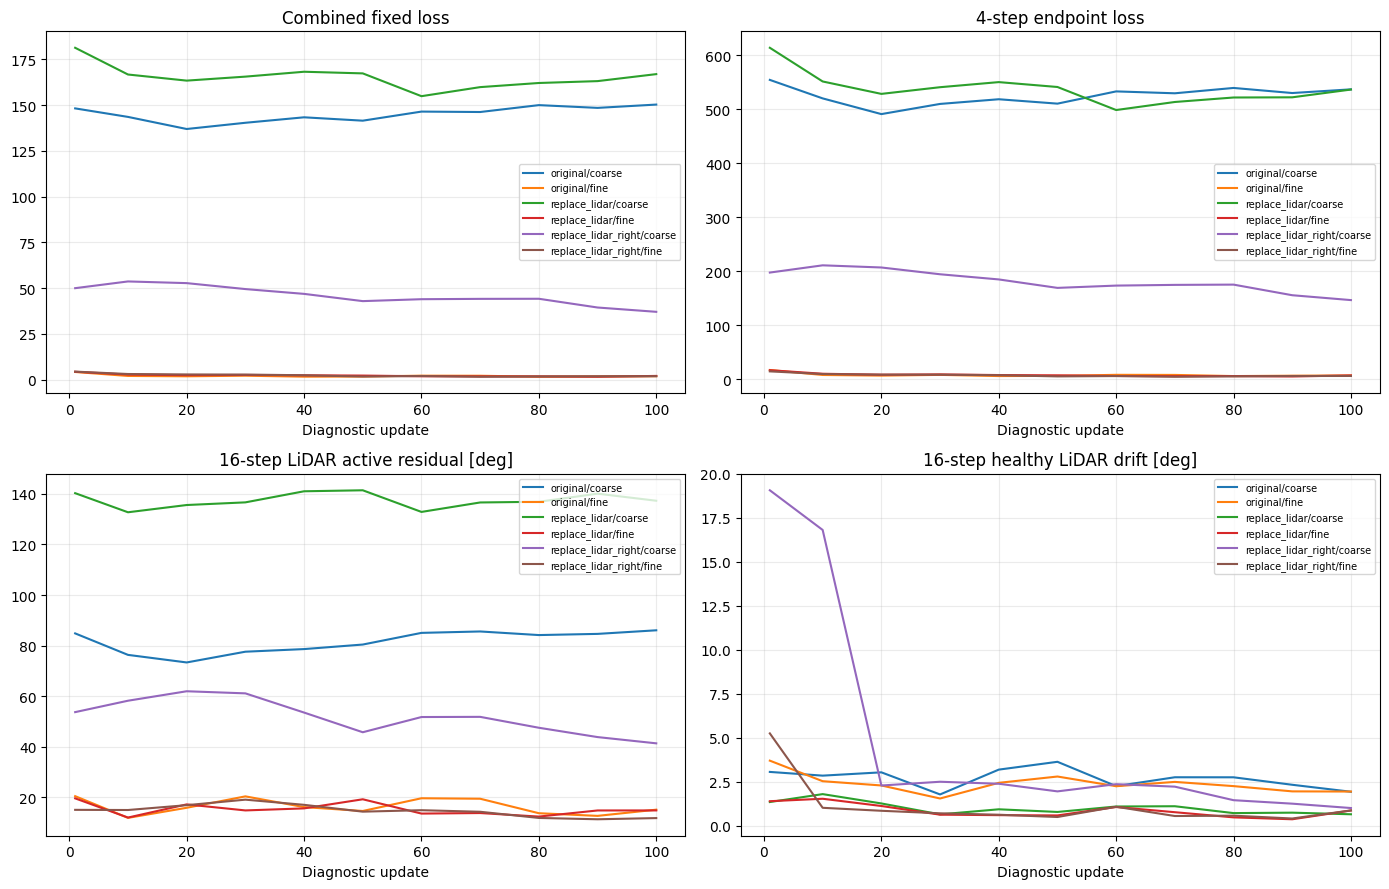

In [12]:
if precheck_history:
    check_df = pd.DataFrame(precheck_history)
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    for (mode, regime), part in check_df.groupby(["topology", "regime"]):
        line = f"{mode}/{regime}"
        axes[0, 0].plot(part.step, part.loss_combined_total, label=line)
        axes[0, 1].plot(part.step, part.loss_endpoint_total, label=line)
        if np.isfinite(part.inference_lidar_active_deg).any():
            axes[1, 0].plot(part.step, part.inference_lidar_active_deg, label=line)
        if np.isfinite(part.inference_lidar_healthy_deg).any():
            axes[1, 1].plot(part.step, part.inference_lidar_healthy_deg, label=line)
    for ax, title in zip(axes.flat, ("Combined fixed loss", "4-step endpoint loss", "16-step LiDAR active residual [deg]", "16-step healthy LiDAR drift [deg]")):
        ax.set(title=title, xlabel="Diagnostic update"); ax.grid(alpha=.25); ax.legend(fontsize=7)
    fig.tight_layout(); plt.show()
else:
    print("No stochastic-check history available")

## 12. Experiment metadata and optional exact-model/optimizer resume
This uses a new FM47 run directory and a fresh optimizer initialized from the selected FM46 source checkpoint. Set RESUME_47_FROM_LAST=True only to resume this same experiment's last.pt, preserving model, optimizer, scheduler and RNG state. Checkpoint history is stored in fm_endpoint_history.csv.

In [13]:
experiment_metadata = {
    "run_name": RUN_NAME, "source_fm_checkpoint": str(SOURCE_FM_CHECKPOINT), "source_regression_checkpoint": str(SOURCE_REGRESSION_CHECKPOINT),
    "architecture": "PooledCalibrationFlowModel", "backbone_config": model_config, "flow_config": flow_config,
    "training_loss": "analytic_lie_velocity_mse_uniform_dense_path", "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS, "flow_path_points": FLOW_PATH_NUM_POINTS, "train_integration_steps": TRAIN_INTEGRATION_STEPS, "train_integration_method": TRAIN_INTEGRATION_METHOD, "velocity_loss_weight": VELOCITY_LOSS_WEIGHT, "endpoint_loss_weight": ENDPOINT_LOSS_WEIGHT, "flow_path_num_points": FLOW_PATH_NUM_POINTS, "flow_path_grid": "linspace(0,1,K)", "true_calibration_config": true_calibration_config,
    "fine_prior_config": fine_prior_config, "coarse_prior_config": coarse_prior_config, "fine_probability": FINE_PRIOR_PROBABILITY,
    "topology_modes": TOPOLOGY_MODES, "topology_probabilities": TOPOLOGY_PROBABILITIES, "fault_key_weights": FAULT_KEY_WEIGHTS,
    "topology_configs": {mode: physical_augmenters[mode].config.sensor_topology for mode in TOPOLOGY_MODES},
    "common_frame_enabled": False, "data_splits": {"train": TRAIN_NAMES, "validation": VAL_NAMES, "test": TEST_NAMES},
}
history = []
start_epoch, global_step, best_validation_loss = 0, 0, float("inf")

RESUME_47_FROM_LAST = False
if RESUME_47_FROM_LAST:
    if not LAST_CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(LAST_CHECKPOINT_PATH)
    load_training_checkpoint(LAST_CHECKPOINT_PATH, model=fm_model, optimizer=optimizer, scheduler=scheduler, map_location=DEVICE, restore_rng_state=True)
    # Only load trusted checkpoint files made by this repository.
    resume_data = torch.load(LAST_CHECKPOINT_PATH, map_location="cpu", weights_only=False)
    start_epoch = int(resume_data["epoch"])
    global_step = int(resume_data["global_step"])
    best_validation_loss = float(resume_data["extra_state"]["best_validation_loss"])
    history_path = RUN_DIR / "fm_endpoint_history.csv"
    if history_path.is_file():
        history = pd.read_csv(history_path).to_dict("records")
        history = [row for row in history if int(row["epoch"]) <= start_epoch]
    if len(optimizer.param_groups) != 2 or fm_model.feature_extractor_frozen:
        raise RuntimeError("Resume expects two fully trainable FM optimizer groups")
    print("Resumed 47 from completed epoch", start_epoch, "steps", global_step)
else:
    print("Fresh dense-path optimizer initialized from source checkpoint weights; no source optimizer loaded.")

Fresh dense-path optimizer initialized from source checkpoint weights; no source optimizer loaded.


In [14]:
model_ids = {id(p) for p in fm_model.parameters() if p.requires_grad}
optimizer_ids = {id(p) for group in optimizer.param_groups for p in group["params"]}

assert model_ids == optimizer_ids, "Optimizer references a different model!"
print("Optimizer and model parameters match.")

Optimizer and model parameters match.


## 13. Optional full training, checkpointed by combined validation objective
Full training is disabled by default and gated on a successful reversible preflight. Run a short pilot with FULL_TRAIN_TOPOLOGY="replace_lidar_right", FULL_TRAIN_REGIME="fine", TRAIN_EPOCHS=5 before mixed training. Scheduler and best.pt follow combined validation, not velocity alone.

In [16]:
if DEVICE.type == "cuda": torch.cuda.empty_cache()

In [ ]:
if RUN_FULL_TRAINING:
    if REQUIRE_PRECHECK_PASS_FOR_FULL_TRAINING and STOCHASTIC_CHECK_PASSED is not True:
        raise RuntimeError("The stochastic precheck has not passed. Review the per-topology fine/coarse curves or opt out explicitly.")
    for epoch in range(start_epoch, TRAIN_EPOCHS):
        train_shuffle_generator.manual_seed(SEED + 12001 + epoch)
        train_metrics = run_topology_fm_epoch(train_loader, training=True, seed=TRAIN_AUG_SEED + 100003 * epoch, topology=FULL_TRAIN_TOPOLOGY, regime=FULL_TRAIN_REGIME, max_batches=MAX_TRAIN_BATCHES_PER_EPOCH)
        val_metrics = run_topology_fm_epoch(val_loader, training=False, seed=VAL_AUG_SEED, max_batches=MAX_VAL_BATCHES_PER_EPOCH)
        mode_metrics = {}
        for mode_idx, mode in enumerate(TOPOLOGY_MODES):
            for regime_idx, regime in enumerate(("fine", "coarse")):
                result = run_topology_fm_epoch(val_loader, training=False, seed=VAL_AUG_SEED + 101 * mode_idx + regime_idx + 2000, topology=mode, regime=regime, max_batches=REGIME_VALIDATION_BATCHES)
                mode_metrics[f"{mode}/{regime}"] = result["loss_combined_total"]
        scheduler.step(val_metrics["loss_combined_total"])
        global_step += train_metrics["optimizer_steps"]
        row = {"epoch": epoch + 1, "train_loss": train_metrics["loss_combined_total"], "val_loss": val_metrics["loss_combined_total"], "train_velocity": train_metrics["loss_fm_total"], "val_velocity": val_metrics["loss_fm_total"], "train_endpoint": train_metrics["loss_endpoint_total"], "val_endpoint": val_metrics["loss_endpoint_total"], "train_seconds": train_metrics["seconds"], "optimizer_steps": train_metrics["optimizer_steps"], **{f"val_{mode}_{regime}": value for (mode, regime), value in ((key.split("/"), val) for key, val in mode_metrics.items())}}
        for mode in TOPOLOGY_MODES:
            row[f"train_topology_n_{mode}"] = train_metrics[f"topology_n/{mode}"]
        history.append(row)
        improved = val_metrics["loss_combined_total"] < best_validation_loss
        if improved:
            best_validation_loss = val_metrics["loss_combined_total"]
            save_training_checkpoint(BEST_CHECKPOINT_PATH, model=fm_model, optimizer=optimizer, scheduler=scheduler, epoch=epoch+1, global_step=global_step, metrics=val_metrics, extra_state={"best_validation_loss": best_validation_loss, "experiment": experiment_metadata})
        save_training_checkpoint(LAST_CHECKPOINT_PATH, model=fm_model, optimizer=optimizer, scheduler=scheduler, epoch=epoch+1, global_step=global_step, metrics=val_metrics, extra_state={"best_validation_loss": best_validation_loss, "experiment": experiment_metadata})
        pd.DataFrame(history).to_csv(RUN_DIR / "fm_endpoint_history.csv", index=False)
        print(f"Epoch {epoch+1:3d}/{TRAIN_EPOCHS} train={train_metrics['loss_fm_total']:.4f} val={val_metrics['loss_fm_total']:.4f} " + " ".join(f"{mode}({mode_metrics[mode+'/fine']:.3f}/{mode_metrics[mode+'/coarse']:.3f})" for mode in TOPOLOGY_MODES) + f" | LRs={optimizer.param_groups[0]['lr']:.1e}/{optimizer.param_groups[1]['lr']:.1e}" + (" BEST" if improved else ""), flush=True)
    if BEST_CHECKPOINT_PATH.is_file():
        load_training_checkpoint(BEST_CHECKPOINT_PATH, model=fm_model, map_location=DEVICE, restore_rng_state=False)
        print("Best FM46 checkpoint selected:", BEST_CHECKPOINT_PATH)
else:
    print("Full training skipped. The loaded model stays at the source checkpoint unless RESUME_46_FROM_LAST=True.")
fm_model.eval()

/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Epoch   1/200 train=16.4441 val=16.2646 original(1.207/126.744) replace_lidar(2.730/48.453) replace_lidar_right(2.062/175.793) | LRs=2.0e-05/2.0e-06 BEST
Epoch   2/200 train=17.0024 val=16.2491 original(1.577/126.614) replace_lidar(2.803/47.566) replace_lidar_right(2.402/174.515) | LRs=2.0e-05/2.0e-06 BEST
Epoch   3/200 train=15.7425 val=16.3862 original(1.522/130.021) replace_lidar(2.533/43.246) replace_lidar_right(2.992/173.967) | LRs=2.0e-05/2.0e-06 BEST
Epoch   4/200 train=17.1341 val=16.1187 original(1.685/125.796) replace_lidar(2.757/44.932) replace_lidar_right(2.116/175.228) | LRs=2.0e-05/2.0e-06 BEST
Epoch   5/200 train=18.0234 val=16.3241 original(1.571/126.481) replace_lidar(2.376/44.291) replace_lidar_right(2.413/176.018) | LRs=2.0e-05/2.0e-06 BEST
Epoch   6/200 train=17.2066 val=16.2377 original(1.534/125.560) replace_lidar(2.766/46.514) replace_lidar_right(1.965/170.909) | LRs=2.0e-05/2.0e-06
Epoch   7/200 train=17.5470 val=16.4011 original(1.371/129.931) replace_lidar(2.3

KeyboardInterrupt: 

## 14. Training and topology-specific validation plots

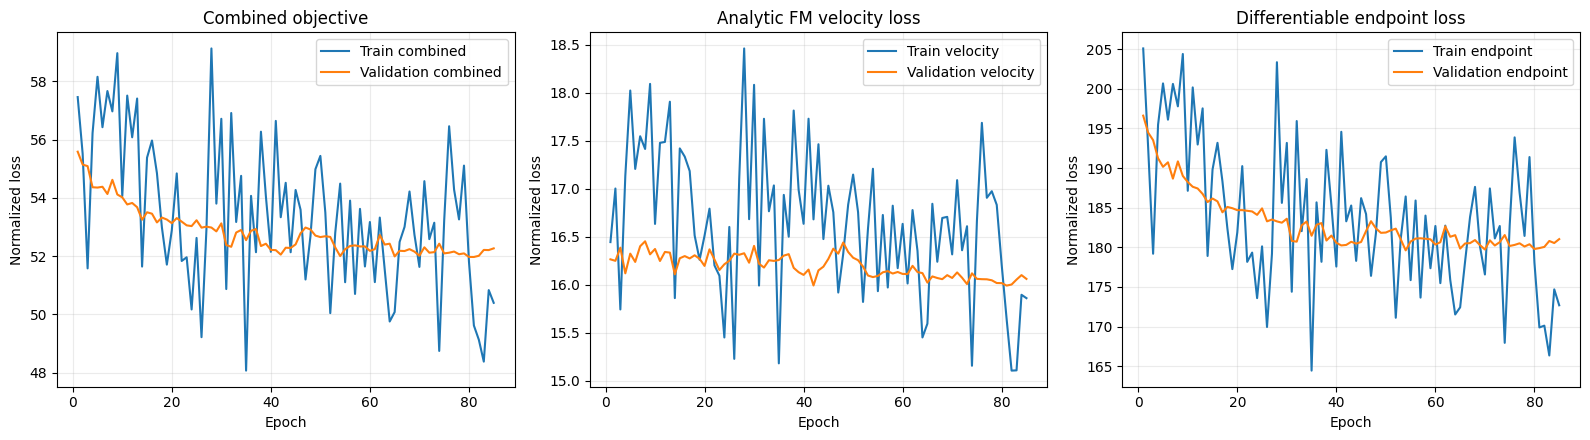

In [18]:
if not history and (RUN_DIR / "fm_endpoint_history.csv").is_file():
    history = pd.read_csv(RUN_DIR / "fm_endpoint_history.csv").to_dict("records")
if history:
    hdf = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    axes[0].plot(hdf.epoch, hdf.train_loss, label="Train combined")
    axes[0].plot(hdf.epoch, hdf.val_loss, label="Validation combined")
    axes[1].plot(hdf.epoch, hdf.train_velocity, label="Train velocity")
    axes[1].plot(hdf.epoch, hdf.val_velocity, label="Validation velocity")
    axes[2].plot(hdf.epoch, hdf.train_endpoint, label="Train endpoint")
    axes[2].plot(hdf.epoch, hdf.val_endpoint, label="Validation endpoint")
    for ax, title in zip(axes, ("Combined objective", "Analytic FM velocity loss", "Differentiable endpoint loss")):
        ax.set(title=title, xlabel="Epoch", ylabel="Normalized loss"); ax.grid(alpha=.25); ax.legend()
    fig.tight_layout(); plt.show()
else:
    print("No training history yet")

## 15. Paired held-out evaluation by topology (optional)
After selecting a notebook 47 checkpoint on validation, compare source FM46 → FM47 → regression 2.24 using identical physical windows, calibration draws and prior perturbations. All models receive the same tokenized cases. Keep the held-out test sequences untouched during tuning and solver selection.

In [ ]:
def sampled_indices_by_sequence(dataset, names, per_sequence: int):
    chosen = []
    for sequence in names:
        indices = np.asarray(dataset.window_indices_for_sequence(sequence), dtype=int)
        if len(indices):
            positions = np.unique(np.linspace(0, len(indices)-1, min(per_sequence, len(indices))).round().astype(int))
            chosen.extend([(sequence, int(indices[i])) for i in positions])
    return chosen

@torch.no_grad()
def paired_topology_evaluation_cases(dataset, names, *, windows_per_sequence=EVAL_WINDOWS_PER_SEQUENCE):
    result = []
    for mode_idx, mode in enumerate(TOPOLOGY_MODES):
        for regime_idx, regime in enumerate(("fine", "coarse")):
            generator = augmentation_generator(TEST_AUG_SEED + 3333 + 100 * mode_idx + regime_idx)
            for sequence, index in sampled_indices_by_sequence(dataset, names, windows_per_sequence):
                base = window_batch_to(collate_windows([dataset[index]]), DEVICE, dtype=DTYPE)
                augmented = augment_topology_window(base, generator, topology=mode, regime=regime)
                tokens, context = tokenize_window(augmented)
                result.append({"sequence": sequence, "index": index, "topology": mode, "regime": regime, "window": augmented, "tokens": tokens, "context": context})
    return result

@torch.no_grad()
def evaluate_paired_model(model, cases, model_name, *, steps=FM_INTEGRATION_STEPS):
    model.eval()
    rows = []
    for case in cases:
        if isinstance(model, PooledCalibrationFlowModel):
            predictions = model(case["tokens"], case["context"], num_steps=steps, method=FM_INTEGRATION_METHOD).predictions
        else:
            predictions = model(case["tokens"], case["context"]).predictions
        xi_truth, tau_truth = correction_targets(case["window"])
        for key, pred in predictions.items():
            current = case["window"].current_calibration[key]
            true = case["window"].targets[key]
            corrected = se3_exp(pred.delta_xi) @ current.transform
            rot0 = torch.rad2deg(torch.linalg.vector_norm(xi_truth[key][:, :3], dim=-1))
            rot1 = torch.rad2deg(torch.linalg.vector_norm(se3_log(true.next_transform @ torch.linalg.inv(corrected))[:, :3], dim=-1))
            trans1 = 100.0 * torch.linalg.vector_norm(corrected[:, :3, 3] - true.next_transform[:, :3, 3], dim=-1)
            tau1 = 1000.0 * torch.abs(current.time_offset + pred.delta_tau - true.next_time_offset).reshape(-1)
            is_active = (torch.linalg.vector_norm(xi_truth[key][:, :3], dim=-1) > 1e-5) | (tau_truth[key].reshape(-1).abs() > 1e-6)
            for i in range(len(rot0)):
                rows.append({"model": model_name, "sequence": case["sequence"], "index": case["index"], "topology": case["topology"], "regime": case["regime"], "key": key,
                             "initial_rotation_deg": rot0[i].item(), "rotation_error_deg": rot1[i].item(), "translation_error_cm": trans1[i].item(), "tau_error_ms": tau1[i].item(), "active_fault": bool(is_active[i].item())})
    return pd.DataFrame(rows)

if RUN_FINAL_EVALUATION:
    if not BEST_CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(f"Train notebook 47 first; no best checkpoint found: {BEST_CHECKPOINT_PATH}")
    load_training_checkpoint(BEST_CHECKPOINT_PATH, model=fm_model, map_location=DEVICE, restore_rng_state=False)
    fm_model.eval()
    evaluation_cases = paired_topology_evaluation_cases(test_dataset, TEST_NAMES)
    predictions_47 = evaluate_paired_model(fm_model, evaluation_cases, "FM 46")
    # Evaluate controls sequentially so GPU does not need to hold three models together.
    source_fm_control = PooledCalibrationFlowModel(flow_config.backbone, **flow_config.model_kwargs()).to(DEVICE, dtype=DTYPE)
    load_training_checkpoint(SOURCE_FM_CHECKPOINT, model=source_fm_control, map_location=DEVICE, restore_rng_state=False)
    source_fm_control.eval().requires_grad_(False)
    predictions_source = evaluate_paired_model(source_fm_control, evaluation_cases, "FM source")
    del source_fm_control
    gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    if SOURCE_REGRESSION_CHECKPOINT.is_file():
        regression_control = PooledCalibrationModel(model_config).to(DEVICE, dtype=DTYPE)
        load_training_checkpoint(SOURCE_REGRESSION_CHECKPOINT, model=regression_control, map_location=DEVICE, restore_rng_state=False)
        regression_control.eval().requires_grad_(False)
        predictions_regression = evaluate_paired_model(regression_control, evaluation_cases, "Regression 2.24")
        del regression_control
    else:
        predictions_regression = pd.DataFrame()
        print("Regression checkpoint missing; compared source FM and FM46 only.")
    evaluation_df = pd.concat([predictions_47, predictions_source, predictions_regression], ignore_index=True)
    evaluation_df.to_csv(RUN_DIR / "fm47_endpoint_paired_test.csv", index=False)
    display(evaluation_df.groupby(["topology", "regime", "model"])[["rotation_error_deg", "translation_error_cm", "tau_error_ms"]].mean().round(3))
    display(evaluation_df[evaluation_df.active_fault].groupby(["topology", "model"])[["rotation_error_deg", "translation_error_cm", "tau_error_ms"]].agg(["mean", "median"]).round(3))
    display(evaluation_df[~evaluation_df.active_fault].groupby(["topology", "model"])[["rotation_error_deg", "tau_error_ms"]].mean().round(3))
else:
    print("Final test evaluation disabled; select a trained checkpoint first.")

rotation_error_deg  \
topology            regime model                                 
original            coarse FM 47                        15.216   
                           FM source                    15.342   
                           Regression 2.24              18.719   
                    fine   FM 47                         4.603   
                           FM source                     2.253   
                           Regression 2.24               1.170   
replace_lidar       coarse FM 47                        26.995   
                           FM source                    28.239   
                           Regression 2.24              27.721   
                    fine   FM 47                         6.822   
                           FM source                     5.485   
                           Regression 2.24               2.415   
replace_lidar_right coarse FM 47                        25.747   
                           FM source                    30.902   
                           Regression 2.24              53.449   
                    fine   FM 47                         4.612   
                           FM source                     5.236   
                           Regression 2.24               3.753   

                                            translation_error_cm  tau_error_ms  
topology            regime model                                                
original            coarse FM 47                          35.698        13.171  
                           FM source                      37.101        16.986  
                           Regression 2.24                42.250        12.503  
                    fine   FM 47                          13.194         6.870  
                           FM source                       6.781         4.757  
                           Regression 2.24                 3.529         7.579  
replace_lidar       coarse FM 47                          53.514        18.396  
                           FM source                      51.433        16.063  
                           Regression 2.24                49.292        33.304  
                    fine   FM 47                          14.393        10.570  
                           FM source                       7.447         7.784  
                           Regression 2.24                 3.446         8.644  
replace_lidar_right coarse FM 47                          38.505        25.120  
                           FM source                      72.588        46.404  
                           Regression 2.24               124.079       103.928  
                    fine   FM 47                          13.273         9.812  
                           FM source                      12.066        11.472  
                           Regression 2.24                 9.258        11.840

rotation_error_deg          \
                                                  mean  median   
topology            model                                        
original            FM 47                       29.064  18.452   
                    FM source                   25.833   9.481   
                    Regression 2.24             29.110   3.985   
replace_lidar       FM 47                       49.917  26.010   
                    FM source                   47.758  15.034   
                    Regression 2.24             42.721  13.320   
replace_lidar_right FM 47                       44.462  36.611   
                    FM source                   51.301  37.867   
                    Regression 2.24             65.782  26.760   

                                    translation_error_cm           \
                                                    mean   median   
topology            model                                           
original            FM 47                         70.583   52.921   
                    FM source                     64.183   26.145   
                    Regression 2.24               66.223    8.632   
replace_lidar       FM 47                         99.681   60.055   
                    FM source                     82.810   18.883   
                    Regression 2.24               73.277   12.704   
replace_lidar_right FM 47                         74.760   56.661   
                    FM source                    119.827  127.551   
                    Regression 2.24              154.226   89.658   

                                    tau_error_ms          
                                            mean  median  
topology            model                                 
original            FM 47                 26.659  17.809  
                    FM source             30.672   9.846  
                    Regression 2.24       23.943   7.820  
replace_lidar       FM 47                 38.099  31.215  
                    FM source             25.576  16.500  
                    Regression 2.24       48.907  51.522  
replace_lidar_right FM 47                 47.327  47.114  
                    FM source             74.930  46.245  
                    Regression 2.24       80.855  39.968

rotation_error_deg  tau_error_ms
topology            model                                            
original            FM 47                         0.333         1.701
                    FM source                     0.279         0.971
                    Regression 2.24               0.362         3.090
replace_lidar       FM 47                         0.404         2.675
                    FM source                     1.415         5.097
                    Regression 2.24               1.242         7.007
replace_lidar_right FM 47                         0.538         2.535
                    FM source                     1.453         5.942
                    Regression 2.24              10.011        46.398

## 16. Optional topology-specific error plots and 4–32-step ablation

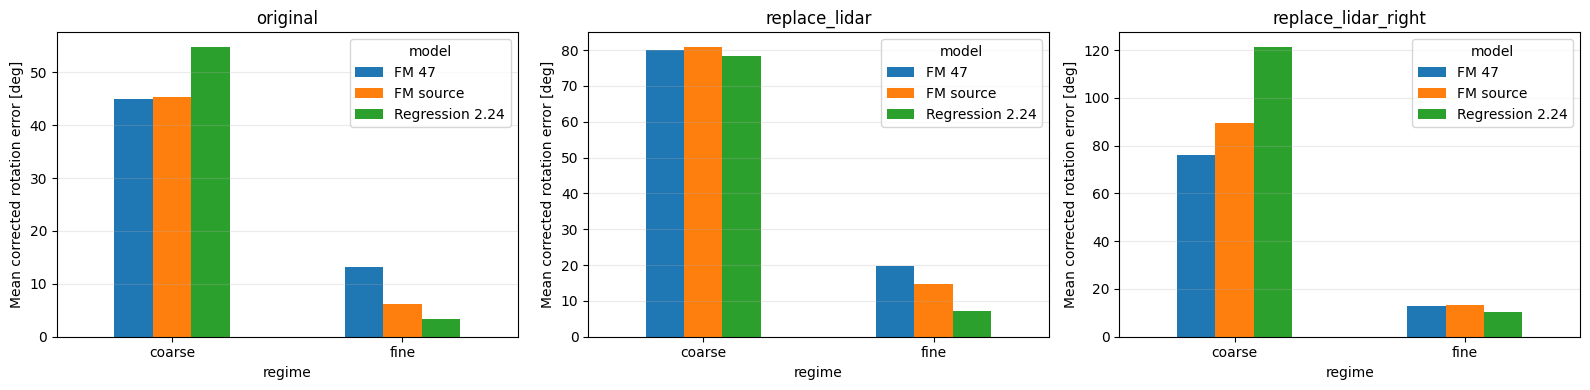

,steps,topology,rotation_mean_deg,tau_mean_ms
0,4,original,34.871,33.440
1,4,replace_lidar,31.737,41.707
2,4,replace_lidar_right,46.892,31.939
3,8,original,37.090,31.741
4,8,replace_lidar,34.235,44.124
5,8,replace_lidar_right,47.679,27.552
6,16,original,37.467,30.630
7,16,replace_lidar,35.662,45.116
8,16,replace_lidar_right,47.774,24.698
9,32,original,38.267,30.268


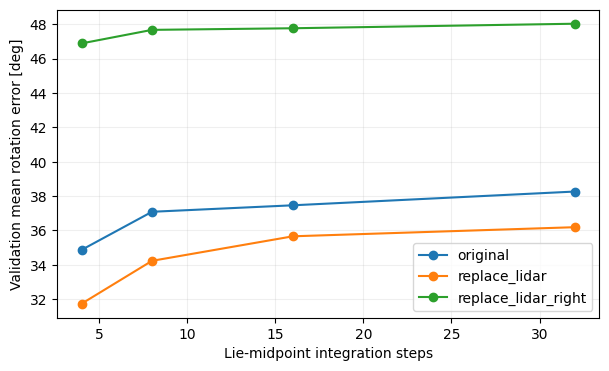

In [22]:
if RUN_FINAL_EVALUATION:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, mode in zip(axes, TOPOLOGY_MODES):
        subset = evaluation_df[(evaluation_df.topology == mode) & (evaluation_df.active_fault)]
        if not subset.empty:
            summary = subset.groupby(["regime", "model"])["rotation_error_deg"].mean().unstack("model")
            summary.plot.bar(ax=ax, rot=0)
        ax.set(title=mode, ylabel="Mean corrected rotation error [deg]")
        ax.grid(axis="y", alpha=.25)
    fig.tight_layout()
    fig.savefig(RUN_DIR / "fm46_topology_paired_rotation.png", dpi=160, bbox_inches="tight")
    plt.show()

if RUN_FINAL_EVALUATION and RUN_INTEGRATION_ABLATION:
    # Must not use test results to tune the integration steps: these are VAL cases.
    validation_cases = paired_topology_evaluation_cases(val_dataset, VAL_NAMES, windows_per_sequence=2)
    step_rows = []
    for steps in ABLATION_STEPS:
        dataframe = evaluate_paired_model(fm_model, validation_cases, "FM 46", steps=steps)
        for mode, group in dataframe[dataframe.active_fault].groupby("topology"):
            step_rows.append({"steps": steps, "topology": mode, "rotation_mean_deg": group.rotation_error_deg.mean(), "tau_mean_ms": group.tau_error_ms.mean()})
    step_df = pd.DataFrame(step_rows)
    display(step_df.round(3))
    step_df.to_csv(RUN_DIR / "fm46_validation_steps.csv", index=False)
    fig, ax = plt.subplots(figsize=(7, 4))
    for mode, frame in step_df.groupby("topology"):
        ax.plot(frame.steps, frame.rotation_mean_deg, "-o", label=mode)
    ax.set(xlabel="Lie-midpoint integration steps", ylabel="Validation mean rotation error [deg]")
    ax.legend(); ax.grid(alpha=.2)
    plt.show()

## 17. Interpretation and next experiment
The combined objective should improve final corrected LiDAR extrinsics and healthy drift, not only velocity MSE. Compare full-training results on fixed, untouched validation windows and test both 1-step Euler and 16-step midpoint inference. If the 4-step endpoint loss remains insufficient, the next separate experiment will supervise correction-to-go velocities from off-path states. Do not introduce that target in this run.